# 06 · Missing Value Imputation
Module 2.1 (Data preparation)

**Imputation** = filling in missing values with sensible estimates so that the rows can still be used.
In this dataset **172 patients (18.7%) have Cholesterol = 0**, which really means "not measured".
We compare three methods:
1. **Mean imputation** - replace every missing value with the average.
2. **Median imputation** - replace with the middle value (robust to outliers and skew).
3. **Regression imputation** - predict the missing cholesterol from the patient's other features with Linear and Ridge regression.

### Setup
We import the usual libraries plus our own `src/` package. `src` holds all reusable code (statistics formulas, outlier detectors, model pipelines, plot styles) so the notebooks and the Streamlit app use exactly the same logic. The random seed is fixed to **42** so every run gives the same numbers.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use our own src/ package
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src import config as C
from src import data, plots
plots.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
np.random.seed(C.RANDOM_STATE)
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

## 1. Mark zeros as missing

In [2]:
df = data.load_clean()
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

Missing values per column:
RestingBP        1
Cholesterol    172
dtype: int64


## 2. Is the missingness random?
If values were missing completely at random, the heart-disease rate would be similar in both groups. Let's check:

In [3]:
miss = df["Cholesterol"].isna()
pd.DataFrame({
    "Patients": [int((~miss).sum()), int(miss.sum())],
    "Heart disease rate": [f"{df.loc[~miss, C.TARGET].mean():.1%}", f"{df.loc[miss, C.TARGET].mean():.1%}"],
}, index=["Cholesterol recorded", "Cholesterol missing"])

,Patients,Heart disease rate
Cholesterol recorded,746,47.7%
Cholesterol missing,172,88.4%


The missing rows are **not random**: almost all patients with missing cholesterol have heart disease (most come from one hospital
that did not record cholesterol). This matters: deleting those rows would throw away many sick patients and bias the data.
That is why we **impute** instead of deleting.

## 3. Predictor features for regression imputation
For the regression method we predict Cholesterol from the other features. We **do not** use the target `HeartDisease` as a predictor,
otherwise the imputed values would carry information about the answer into the model later (data leakage).
Categorical features are one-hot encoded (turned into 0/1 columns).

In [4]:
predictors = ["Age", "RestingBP", "MaxHR", "Oldpeak", "Sex", "ChestPainType", "FastingBS", "RestingECG",
              "ExerciseAngina", "ST_Slope"]
X_all = pd.get_dummies(df[predictors], drop_first=True, dtype=float)
X_all["RestingBP"] = X_all["RestingBP"].fillna(X_all["RestingBP"].median())   # the 1 missing BP value
print("Predictor matrix shape:", X_all.shape)

Predictor matrix shape: (918, 14)


## 4. Fair comparison: hide some known values and try to recover them
We cannot measure the error on the truly missing values (we do not know their real values). So we take the **746 rows where
cholesterol is known**, randomly **hide 20%** of them, impute those with each method, and compare the imputed values with the real ones
using **MAE** (mean absolute error) and **RMSE** (root mean squared error). Lower is better.

In [5]:
known = df.index[~miss]
rng = np.random.default_rng(C.RANDOM_STATE)
hidden = rng.choice(known, size=int(0.2 * len(known)), replace=False)
train_idx = known.difference(hidden)
y_true = df.loc[hidden, "Cholesterol"]
y_train = df.loc[train_idx, "Cholesterol"]

def regression_imputer(model):
    pipe = make_pipeline(StandardScaler(), model)
    pipe.fit(X_all.loc[train_idx], y_train)
    return pipe

estimates = {
    "Mean": np.full(len(hidden), y_train.mean()),
    "Median": np.full(len(hidden), y_train.median()),
    "Linear regression": regression_imputer(LinearRegression()).predict(X_all.loc[hidden]),
    "Ridge regression (α=10)": regression_imputer(Ridge(alpha=10)).predict(X_all.loc[hidden]),
}
scores = pd.DataFrame({
    "MAE (mg/dl)": {k: mean_absolute_error(y_true, v) for k, v in estimates.items()},
    "RMSE (mg/dl)": {k: np.sqrt(mean_squared_error(y_true, v)) for k, v in estimates.items()},
})
scores.round(2)

,MAE (mg/dl),RMSE (mg/dl)
Mean,43.510,56.610
Median,42.210,56.110
Linear regression,44.340,57.060
Ridge regression (α=10),44.280,57.020


## 5. Impute the real missing values with each method
Now we fit each method on **all** known rows and fill the 172 truly missing values.

In [6]:
X_known, y_known = X_all.loc[known], df.loc[known, "Cholesterol"]
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_known, y_known)
ridge = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(X_known, y_known)

versions = {}
for name, fill in {
    "Mean": np.full(miss.sum(), y_known.mean()),
    "Median": np.full(miss.sum(), y_known.median()),
    "Linear regression": lin.predict(X_all.loc[miss]),
    "Ridge regression (α=10)": ridge.predict(X_all.loc[miss]),
}.items():
    col = df["Cholesterol"].copy()
    col.loc[miss] = fill
    versions[name] = col

summary = pd.DataFrame({name: {"Mean": s.mean(), "Median": s.median(), "Std": s.std(),
                               "Imputed values: min": s[miss].min(), "Imputed values: max": s[miss].max()}
                        for name, s in versions.items()}).T
summary.loc["Original (known values only)"] = [y_known.mean(), y_known.median(), y_known.std(), np.nan, np.nan]
summary.round(2)

,Mean,Median,Std,Imputed values: min,Imputed values: max
Mean,244.640,244.640,53.320,244.640,244.640
Median,243.200,237.000,53.400,237.000,237.000
Linear regression,244.280,240.140,53.590,211.060,288.440
Ridge regression (α=10),244.300,240.300,53.580,211.420,287.850
Original (known values only),244.640,237.000,59.150,NaN,NaN


## 6. Effect on the distribution
Mean/median imputation puts all 172 values at one single number, creating an artificial spike and **shrinking the standard deviation**.
Regression imputation spreads the imputed values according to each patient's other features - but because those features predict cholesterol poorly, the spread is narrow.

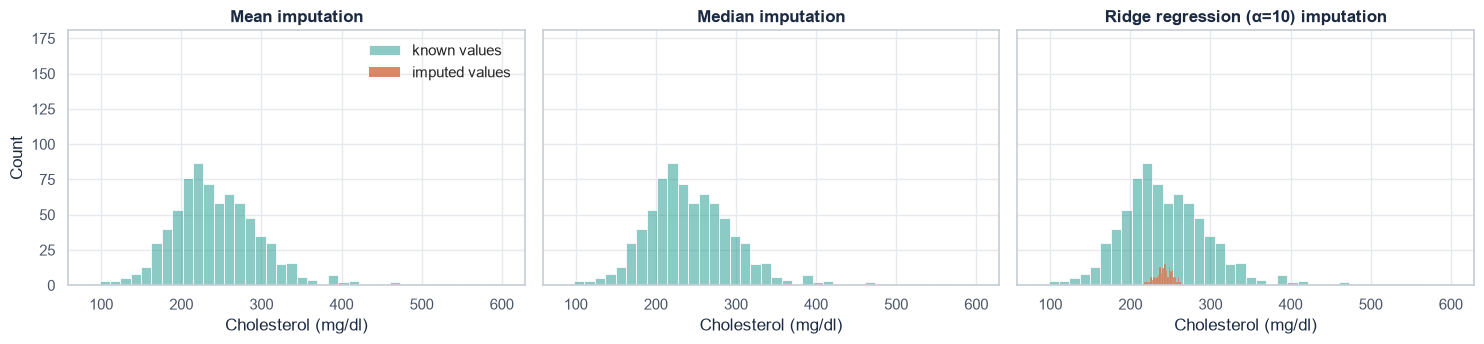

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, name in zip(axes, ["Mean", "Median", "Ridge regression (α=10)"]):
    sns.histplot(versions[name][~miss], bins=40, ax=ax, color=C.TEAL, alpha=0.45, label="known values")
    sns.histplot(versions[name][miss], bins=40, ax=ax, color=C.CLASS_COLORS[1], alpha=0.8, label="imputed values")
    ax.set_title(f"{name} imputation")
    ax.set_xlabel("Cholesterol (mg/dl)")
axes[0].legend(frameon=False)
fig.tight_layout()
plots.save_fig(fig, "06_imputation_comparison")
plt.show()

## 7. Save processed versions
We save the median- and ridge-imputed datasets. **Note on the final model (notebook 07):** there we do *not* use these files.
Instead, a `SimpleImputer(strategy="median")` sits **inside** the sklearn Pipeline, so the median is learned from the training folds only
(no leakage). Median was chosen because it is robust to the heavy right tail of cholesterol and had the lowest error in the comparison above.

In [8]:
for name, fname in [("Median", "heart_imputed_median.csv"), ("Ridge regression (α=10)", "heart_imputed_ridge.csv")]:
    out = df.copy()
    out["Cholesterol"] = versions[name].round(1)
    out["RestingBP"] = out["RestingBP"].fillna(out["RestingBP"].median())
    out.to_csv(C.PROCESSED_DIR / fname, index=False)
    print("Saved:", (C.PROCESSED_DIR / fname).relative_to(C.ROOT))

Saved: data\processed\heart_imputed_median.csv
Saved: data\processed\heart_imputed_ridge.csv


## Key Findings
* **172 Cholesterol values (18.7%) and 1 RestingBP value** were missing (stored as 0).
* The missingness is **not random**: 88% of patients with missing cholesterol have heart disease vs 48% of the others, so deleting those rows would bias the data. Imputation keeps them.
* In the hide-and-recover test, **median imputation had the lowest error (MAE ≈ 42.2 mg/dl)**, mean was close (43.5), and Linear/Ridge regression were slightly worse (≈ 44.3). The other features explain very little of cholesterol (correlations below 0.1 in notebook 03), so regression has little to learn from.
* Mean/median imputation create a **spike** at one value and shrink the standard deviation (59.2 → 53.4). Regression imputation spreads the imputed values (≈ 211–288 mg/dl), but still in a narrow range.
* Decision: the final model uses **median imputation inside the sklearn Pipeline** - simplest, most robust to the skewed tail, as accurate as the alternatives, and leakage-free.